## WEEK 2

## • Clean and preprocess the dataset.


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

df = pd.read_csv("../data/train_v2_drcat_02.csv")
print(df.shape)
df.head()

(44868, 5)


,text,label,prompt_name,source,RDizzl3_seven
0,Phones\n\nModern humans today are always on th...,0,Phones and driving,persuade_corpus,False
1,This essay will explain if drivers should or s...,0,Phones and driving,persuade_corpus,False
2,Driving while the use of cellular devices\n\nT...,0,Phones and driving,persuade_corpus,False
3,Phones & Driving\n\nDrivers should not be able...,0,Phones and driving,persuade_corpus,False
4,Cell Phone Operation While Driving\n\nThe abil...,0,Phones and driving,persuade_corpus,False


## Analyze features, missing values and target distribution.

In [6]:
print(df.isna().sum())
print("Duplicated texts:", df.duplicated("text").sum())

text             0
label            0
prompt_name      0
source           0
RDizzl3_seven    0
dtype: int64
Duplicated texts: 0


In [7]:
df["n_words"] = df["text"].str.split().str.len()
print(df.groupby("label")["n_words"].describe())

         count        mean         std    min    25%    50%    75%     max
label                                                                     
0      27371.0  418.283146  189.285918  143.0  274.0  383.0  519.0  1656.0
1      17497.0  329.398983   94.256529    4.0  274.0  328.0  386.0   818.0


In [8]:
print(pd.crosstab(df["source"], df["label"]))
print(df["prompt_name"].value_counts())

label                                   0     1
source                                         
NousResearch/Llama-2-7b-chat-hf         0   400
chat_gpt_moth                           0  2421
cohere-command                          0   350
darragh_claude_v6                       0  1000
darragh_claude_v7                       0  1000
falcon_180b_v1                          0  1055
kingki19_palm                           0  1384
llama2_chat                             0  2421
llama_70b_v1                            0  1172
mistral7binstruct_v1                    0  2421
mistral7binstruct_v2                    0  2421
mistralai/Mistral-7B-Instruct-v0.1      0   400
palm-text-bison1                        0   349
persuade_corpus                     25996     0
radek_500                               0   500
radekgpt4                               0   200
train_essays                         1375     3
prompt_name
Distance learning                        5554
Seeking multiple opinions     

## • Define training, validation and test sets.


In [9]:
data, _ = train_test_split(df, train_size=10000, stratify=df["label"], random_state=0)
train, test = train_test_split(data, test_size=0.2, stratify=data["label"], random_state=0)

print(train.shape, test.shape)
print(train["label"].value_counts(normalize=True))
print(test["label"].value_counts(normalize=True))

train.to_csv("../data/train.csv", index=False)
test.to_csv("../data/test.csv", index=False)

(8000, 6) (2000, 6)
label
0    0.61
1    0.39
Name: proportion, dtype: float64
label
0    0.61
1    0.39
Name: proportion, dtype: float64


## • Select and implement a baseline model.


In [19]:
X_train = train["text"]
y_train = train["label"]
cv = StratifiedKFold(5, shuffle=True, random_state=0)
metrics = ["accuracy", "f1", "precision","recall","roc_auc"]

## Baseline 1 : Dummy Model

In [20]:
dummy = DummyClassifier(strategy="most_frequent")
results = cross_validate(dummy, X_train, y_train, cv=cv, scoring=metrics)
for m in metrics:
    print(m, results["test_" + m].mean())

accuracy 0.61
f1 0.0
precision 0.0
recall 0.0
roc_auc 0.5


c:\Users\idris\anaconda3\envs\genai\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\idris\anaconda3\envs\genai\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\idris\anaconda3\envs\genai\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\idris\anac

- We use a dummy model as our first baseline, it always predicts the most frequent class (human) without reading the texts. 
We used it because it gives the minimum score that any real model must beat, so it helps us check that our future models really learned something from the texts.

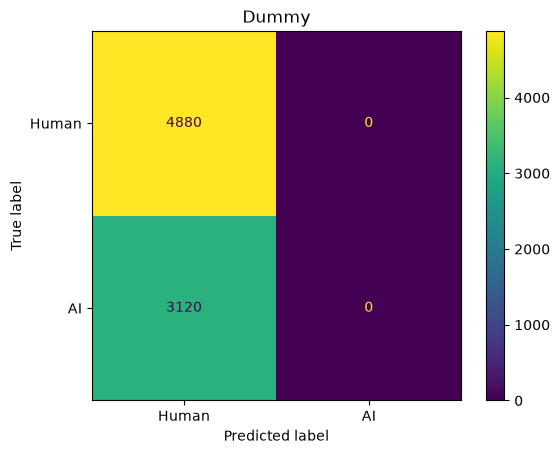

In [21]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay

y_pred = cross_val_predict(dummy, X_train, y_train, cv=cv)

ConfusionMatrixDisplay.from_predictions(y_train, y_pred, display_labels=["Human", "AI"])
plt.title("Dummy")
plt.show()

Confusion matrix : 
- All the human essays are correctly classified, but all the AI essays are misclassified. So the model has no false positive, but it never detects any AI essay so it has no true positive either, which gives a recall and a precision of 0.
This shows that accuracy alone is not a good metric for our problem. The 61% accuracy only comes from the class imbalance, and the model does not distinguish the two classes at all and never predicts the minority class.